# Lab 4.1 — Detectar data drift en producción

**Curso:** AWS Certified Machine Learning Engineer – Associate (MLA-C02) · **Tema:** 4.1

Reproduce localmente lo que hacen las soluciones de monitoreo de SageMaker AI (MLflow + Evidently AI) o SageMaker Model Monitor:

1. Calcular una línea base con los datos de entrenamiento.
2. Medir el drift de cada lote con **PSI** y **Kolmogorov-Smirnov**, con umbrales de alerta.
3. Detectar errores de calidad de datos con restricciones.
4. Ver por qué la calidad del modelo solo se conoce **cuando llegan las etiquetas**.

No requiere cuenta de AWS ni credenciales.

## 0. Preparación

Los módulos reutilizables están en `src/`.

In [1]:
import sys

sys.path.insert(0, "src")

In [2]:
from pathlib import Path

import pandas as pd

import drift
import generate_data as gen
import model
import plots

LANG = "es"
LABEL_DELAY = 3  # semanas hasta conocer si hubo fraude / weeks until fraud labels are known
pd.set_option("display.width", 120)

## 1. Datos

Un modelo de fraude en pagos con tarjeta. La referencia (entrenamiento) tiene 10.000 transacciones; producción, 14 lotes semanales de 2.000. El generador introduce a propósito:

| Variable | Qué cambia |
|---|---|
| `amount` | Drift **gradual**: el importe sube un poco cada semana. |
| `channel` | Drift **brusco** en la semana 6: una campaña lleva tráfico a la app. |
| `customer_age`, `account_age_days` | Estables: sirven de control. |
| `customer_age` | Semana 11: 8 % de valores faltantes por un error del pipeline. |
| Etiqueta `fraud` | Semana 9: cambia el patrón de fraude (**concept drift**) sin cambiar las distribuciones. |

In [3]:
ref = gen.reference()
prod = gen.production()
Path("data").mkdir(exist_ok=True)
ref.to_csv("data/reference.csv", index=False)
prod.to_csv("data/production.csv", index=False)
print(f"reference={len(ref):,}  production={len(prod):,} ({prod['week'].nunique()} weeks)  fraud rate={ref['fraud'].mean():.1%}")
ref.head()

reference=10,000  production=28,000 (14 weeks)  fraud rate=7.0%


,amount,customer_age,account_age_days,channel,fraud
0,44.75,32.0,784.0,app,0
1,58.49,41.0,282.0,web,0
2,34.93,32.0,377.0,app,0
3,20.05,68.0,605.0,web,0
4,29.69,52.0,698.0,web,0


## 2. Línea base

Se calcula **una vez** con los datos de entrenamiento: estadísticas, deciles (los bins del PSI) y proporciones de categorías. Equivale a `statistics.json` y `constraints.json` de Model Monitor.

In [4]:
base = drift.baseline(ref, gen.NUMERIC, gen.CATEGORICAL)
stats = pd.DataFrame(base["numeric"]).T[["mean", "std", "min", "p50", "max", "missing"]].astype(float).round(2)
print(base["categorical"]["channel"]["proportions"].round(3).to_dict())
stats

{'web': 0.504, 'app': 0.344, 'pos': 0.153}


,mean,std,min,p50,max,missing
amount,66.05,74.10,1.66,44.16,1729.25,0.0
customer_age,41.12,11.60,18.00,41.00,88.00,0.0
account_age_days,447.93,360.79,0.00,354.00,3170.00,0.0


## 3. PSI por variable y por semana

**PSI** (*Population Stability Index*) compara la proporción de datos en cada bin de la referencia con la del lote:

PSI = Σ (actual − esperado) · ln(actual / esperado)

Umbrales: **< 0,1** estable, **0,1–0,2** aviso, **≥ 0,2** alerta. Son una **convención habitual** (viene del riesgo crediticio), **no una regla de AWS**: ajústalos a cada variable y caso.

In [5]:
report = drift.monitor(base, ref, prod)
report.pivot(index="week", columns="feature", values="psi").round(3)

feature,account_age_days,amount,channel,customer_age
week,,,,
1,0.008,0.004,0.002,0.005
2,0.003,0.038,0.001,0.004
3,0.003,0.026,0.000,0.009
4,0.006,0.031,0.002,0.003
5,0.005,0.055,0.001,0.003
6,0.010,0.082,0.254,0.011
7,0.005,0.102,0.263,0.007
8,0.005,0.135,0.268,0.006
9,0.006,0.147,0.325,0.005


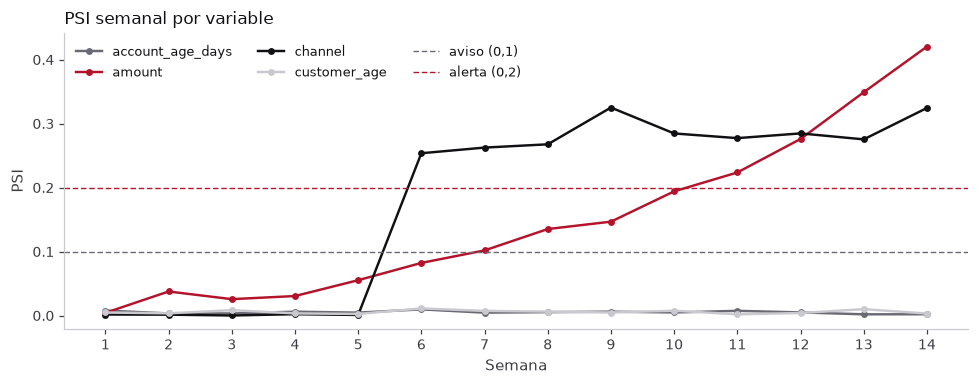

In [6]:
plots.psi_over_time(report, LANG);

In [7]:
report.pivot(index="week", columns="feature", values="status")

feature,account_age_days,amount,channel,customer_age
week,,,,
1,ok,ok,ok,ok
2,ok,ok,ok,ok
3,ok,ok,ok,ok
4,ok,ok,ok,ok
5,ok,ok,ok,ok
6,ok,ok,alert,ok
7,ok,warning,alert,ok
8,ok,warning,alert,ok
9,ok,warning,alert,ok


- `channel` salta a alerta en la semana 6: un cambio brusco se ve de inmediato.
- `amount` sube poco a poco: un drift gradual pasa desapercibido semanas enteras si solo miras un lote contra el anterior. Por eso se compara siempre contra la **línea base**.
- Las variables estables quedan muy por debajo de 0,1.

## 4. Kolmogorov-Smirnov: significativo no es lo mismo que importante

KS compara las distribuciones acumuladas de dos muestras. Su p-valor depende del tamaño de muestra: con 2.000 filas por lote, cambios pequeños ya son «significativos». Además, con muchas pruebas por semana, algunas fallan por azar.

In [8]:
ks = report[report["feature"] != "channel"].pivot(index="week", columns="feature", values=["ks_stat", "ks_pvalue"])
ks.round(4)

ks_stat                             ks_pvalue                     
feature account_age_days  amount customer_age account_age_days  amount customer_age
week                                                                               
1                 0.0280  0.0244       0.0195           0.1447  0.2713       0.5462
2                 0.0152  0.0803       0.0140           0.8322  0.0000       0.8965
3                 0.0252  0.0632       0.0246           0.2378  0.0000       0.2626
4                 0.0112  0.0769       0.0160           0.9840  0.0000       0.7829
5                 0.0199  0.1001       0.0179           0.5198  0.0000       0.6551
6                 0.0385  0.1201       0.0187           0.0140  0.0000       0.6001
7                 0.0288  0.1332       0.0236           0.1243  0.0000       0.3080
8                 0.0137  0.1599       0.0195           0.9103  0.0000       0.5462
9                 0.0169  0.1691       0.0346           0.7235  0.0000       0.0364
10                0.0327  0.1805       0.0254           0.0558  0.0000       0.2299
11                0.0194  0.2012       0.0130           0.5528  0.0000       0.9533
12                0.0224  0.2193       0.0137           0.3695  0.0000       0.9103
13                0.0126  0.2483       0.0195           0.9520  0.0000       0.5462
14                0.0142  0.2681       0.0248           0.8867  0.0000       0.2541

In [9]:
amount = report[report["feature"] == "amount"].set_index("week")
print("amount: first week with KS p<0.05 :", amount.index[amount["ks_pvalue"] < 0.05].min())
print("amount: first week with PSI >= 0.1:", amount.index[amount["psi"] >= drift.PSI_WARNING].min())
stable = report[report["feature"].isin(["customer_age", "account_age_days"])]
print(f"stable features: {(stable['ks_pvalue'] < 0.05).sum()} of {len(stable)} KS tests with p<0.05 (false alarms)")

amount: first week with KS p<0.05 : 2
amount: first week with PSI >= 0.1: 7
stable features: 2 of 28 KS tests with p<0.05 (false alarms)


Usa el **estadístico** (PSI o el KS *D*) como tamaño del efecto para alertar, y el p-valor solo como apoyo.

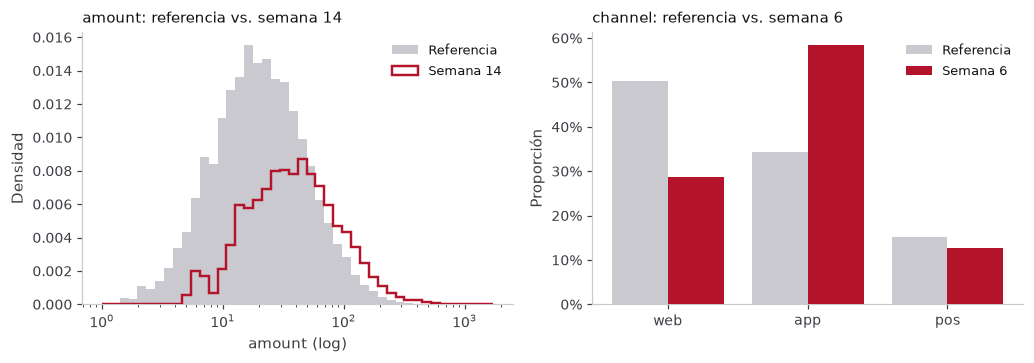

In [10]:
plots.overlays(ref, prod, amount_week=14, channel_week=6, lang=LANG);

## 5. Restricciones de calidad de datos

El drift no es el único problema: un error del pipeline también cambia los datos. La restricción de completitud compara los faltantes con la línea base.

In [11]:
report.loc[report["violations"].str.len() > 0, ["week", "feature", "psi", "missing", "violations"]]

,week,feature,psi,missing,violations
41,11,customer_age,0.002005,0.0895,[completeness: 8.9% missing (baseline 0.0%)]


El PSI de `customer_age` no se mueve porque ignora los faltantes; solo la restricción lo detecta. Monitorea **las dos cosas**.

## 6. Calidad del modelo y retraso de etiquetas

Si una transacción fue fraude se sabe semanas después (contracargos). Con `LABEL_DELAY = 3`, la AUC del lote de la semana *w* se conoce en la semana *w + 3*. `flagged_rate` (la proporción de alertas del modelo) sí se conoce al instante.

In [12]:
fraud_model = model.train(ref)
quality = model.weekly_quality(fraud_model, prod, LABEL_DELAY)
quality.round(3)

,week,flagged_rate,fraud_rate,auc,recall,known_at_week
0,1,0.050,0.080,0.862,0.354,4
1,2,0.056,0.074,0.846,0.320,5
2,3,0.054,0.077,0.857,0.318,6
3,4,0.058,0.075,0.861,0.373,7
4,5,0.072,0.086,0.816,0.314,8
5,6,0.053,0.072,0.875,0.371,9
6,7,0.066,0.076,0.864,0.408,10
7,8,0.069,0.074,0.837,0.429,11
8,9,0.072,0.068,0.594,0.103,12
9,10,0.086,0.060,0.614,0.167,13


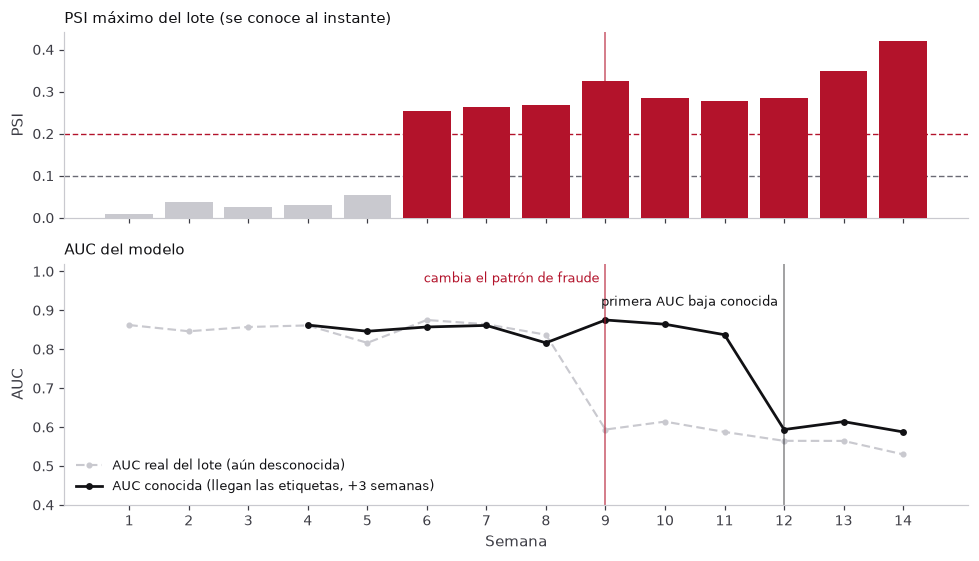

In [13]:
plots.label_delay(report, quality, gen.CONCEPT_WEEK, LABEL_DELAY, LANG);

- **Drift sin degradación**: `channel` y `amount` disparan alertas desde la semana 6, pero la AUC se mantiene. El drift es una señal para investigar, no una prueba de que el modelo falle.
- **Degradación sin drift**: en la semana 9 cambia el patrón de fraude. Las entradas siguen igual, así que el PSI y `flagged_rate` no lo ven. La caída de la AUC solo aparece en la semana 12, cuando llegan las etiquetas.
- Para acortar ese hueco: etiquetar una muestra antes (revisión manual) o vigilar indicadores de negocio, como las reclamaciones.

## 7. Equivalencia en AWS

SageMaker Model Monitor ya no acepta clientes nuevos. Su reemplazo documentado son las soluciones de monitoreo open source de SageMaker AI (SageMaker AI MLflow Apps + Evidently AI), paneles de Amazon QuickSight y Amazon CloudWatch.

| Este laboratorio | En AWS | Diferencias principales |
|---|---|---|
| `drift.baseline` | Línea base de Model Monitor (`statistics.json`, `constraints.json`) o el dataset de referencia de Evidently | En AWS, el dataset de entrenamiento se lee como referencia desde S3. |
| `drift.drift_report` (PSI, KS) | Evidently `DataDriftPreset`, ejecutado por una SageMaker Pipeline o una Lambda programada con EventBridge | Evidently calcula PSI y KS para cada variable y genera informes HTML que se registran en una MLflow App. |
| Restricción de completitud | Evidently `DataSummaryPreset` o restricciones de Model Monitor | Más comprobaciones: tipos, rangos y valores atípicos. |
| `model.weekly_quality` con retraso | Evidently `ClassificationPreset` al llegar el ground truth, unido a las predicciones por ID de inferencia | En un endpoint, Data Capture guarda entradas y salidas en S3. |
| `status` y umbrales | Alertas con Amazon SNS; métricas personalizadas y alarmas de detección de anomalías en CloudWatch | El pipeline batch de ejemplo alerta por defecto cuando deriva más del 30 % de las variables. |

### Prueba esto

- Cambia `LABEL_DELAY` a 1 y mira cuándo se detecta la caída.
- Usa 5 bins en `drift.baseline(..., bins=5)` y compara el PSI de `amount`.
- Reduce `N_BATCH` en `generate_data.py` a 300 y observa cómo cambian los p-valores de KS.